In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT: STUDENT MATHEMATICS PERFORMANCE ANALYSIS
    STAGE 1
i. Load and Understand the dataSET
ii. gain understanding of the size, structure, variables and data types



In [2]:
# Load the student csv data 
data = pd.read_csv("data/student-mat.csv", sep = ";")

In [3]:
# Check the first 5 rows of the data
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# Check the size of the data

data.shape

(395, 33)

In [5]:
# Lets find out the variables in our data by checking the columns

data.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
# Check the data types and lookout for missing missing values

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### Step 1.6: Review the Dataset Documentation and Understand Key Variables

Before selecting the target variable, the dataset documentation was reviewed to understand the meaning of the variables. 
According to the UCI Machine Learning Repository, G1 represents the first-period grade, G2 represents the second-period grade, and G3 represents the final grade. G3 is identified as the output target in the original dataset documentation.

### Step 1.7: Define the Target Variable and Prediction Problem

The target variable for this project is `G3`, which represents the student's final Mathematics grade on a scale of 0 to 20.

The initial machine learning objective is to investigate whether students' final Mathematics grades can be predicted using information available in the dataset.

Because `G3` is numerical, predicting its actual value is initially treated as a regression problem.

In [7]:
# Next is to understand the target variable

data["G3"].head()

0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

### Step 1.8: Perform Descriptive Analysis of the Target Variable


Before building a machine learning model, the target variable should be examined to understand its range, central tendency, spread, and distribution. This helps identify unusual values and provides an initial picture of student performance.

In [8]:
# Determine the minimum value in G3

data["G3"].min()

0

In [9]:
# Determine the maximum value in G3

data["G3"].max()

20

In [10]:
# Find the average G3 grade of students 

round(data["G3"].mean(), 2)

np.float64(10.42)

In [11]:
# Calculate the median and mode of G3

data["G3"].median()

11.0

In [12]:
data["G3"].mode()

0    10
Name: G3, dtype: int64

In [13]:
# lets get the descriptive statistics summary of the target

data["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

### Inspecting the frequency distribution of final grade

In [14]:
data["G3"].value_counts().sort_index()

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

In [15]:
# next, lets count the number of students with zero as their final grade

zero_grade_count = (data["G3"]==0).sum()

In [16]:
print(zero_grade_count)

38


### Time to visualize our data. 
we're going to create a bar chsrt of the different G3 
grades and the number of students that recorded those grades

In [17]:
# Select the targel column, count how many students obtained each grade and then sort then in ascending order

grade_counts = data["G3"].value_counts().sort_index()

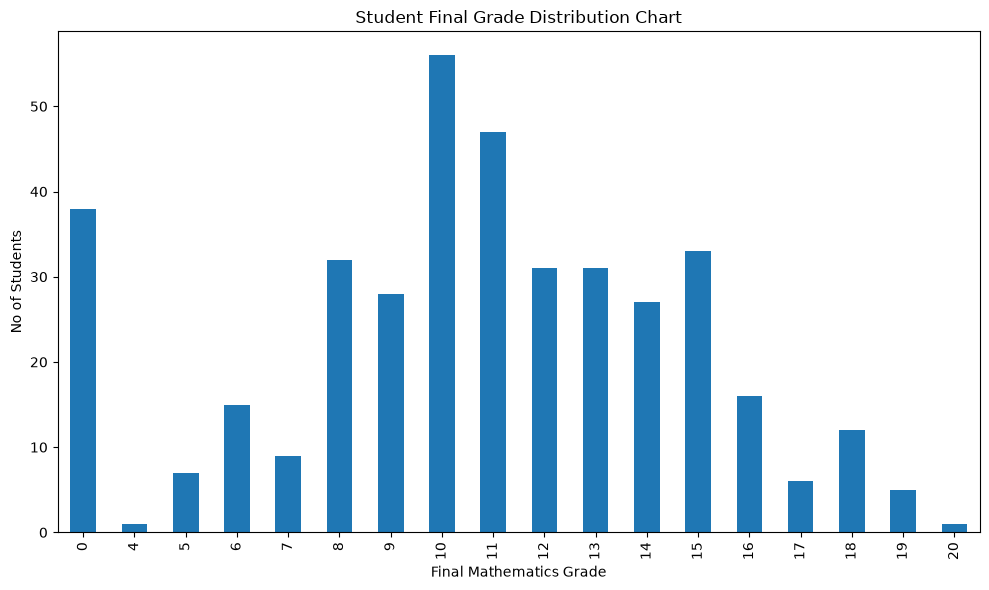

In [18]:
plt.figure(figsize=(10, 6))
grade_counts.plot(kind = "bar")

plt.xlabel("Final Mathematics Grade")
plt.ylabel("No of Students")
plt.title("Student Final Grade Distribution Chart")

plt.tight_layout()
plt.savefig("g3_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## Stage 2: Investigating The Final Grades of Zero

### Stage 2: Investigating Students With a Zero Final Mathematics Grade
Evidence from the target variable revealed that 38 students scored zero in their third mathematics grade. Therefore, I want to study that group of students futher. Investigating their grades in Mathes grade 1 and 2 G1 and G2 respectively as well as their absence records to learn about their earlier academic behaviours  

In [19]:
student_with_zero_g3 = data[data["G3"] == 0]

In [20]:
student_with_zero_g3.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
128,GP,M,18,R,GT3,T,2,2,services,other,...,3,3,3,1,2,4,0,7,4,0
130,GP,F,15,R,GT3,T,3,4,services,teacher,...,4,2,2,2,2,5,0,12,0,0
131,GP,F,15,U,GT3,T,1,1,at_home,other,...,4,3,3,1,2,4,0,8,0,0
134,GP,M,15,R,GT3,T,3,4,at_home,teacher,...,5,3,3,1,1,5,0,9,0,0
135,GP,F,15,U,GT3,T,4,4,services,at_home,...,4,3,3,1,1,5,0,11,0,0


In [21]:
# Check the size of G3 to be sure the currect size is displayed
student_with_zero_g3.shape

(38, 33)

In [22]:
# Also check to be sure only grade zeros are filtered 

student_with_zero_g3["G3"].unique()

array([0])

In [23]:
# I want to study these students all three grades and absence record. so lets seperate that data

student_with_zero_g3[["G1", "G2", "G3", "absences"]].head(10)

,G1,G2,G3,absences
128,7,4,0,0
130,12,0,0,0
131,8,0,0,0
134,9,0,0,0
135,11,0,0,0
136,10,0,0,0
137,4,0,0,0
140,7,9,0,0
144,5,0,0,0
146,6,7,0,0


In [24]:
# View their G1, G2 and absences statistical records

student_with_zero_g3[["G1", "G2", "absences"]].describe()

,G1,G2,absences
count,38.000000,38.000000,38.0
mean,7.526316,4.657895,0.0
std,1.811925,3.700083,0.0
min,4.000000,0.000000,0.0
25%,6.000000,0.000000,0.0
50%,7.000000,5.000000,0.0
75%,9.000000,8.000000,0.0
max,12.000000,10.000000,0.0


Among the 38 students who recorded a final Mathematics grade of zero, the mean first-period grade (G1) was approximately 7.53, while the mean second-period grade (G2) was approximately 4.66. Performance in the first period varied, with G1 scores ranging from 4 to 12, while G2 scores ranged from 0 to 10. This indicates that although the group generally recorded relatively low prior performance, not all the students had previously obtained zero grades. Notably, all 38 students had zero recorded absences. Therefore, based on the available absence variable, there is no evidence that frequent recorded absenteeism explains the zero final grades observed in this group.



## Stage 3: Comparative Analysis
Compare Groups with zero and those with non-grades group to determine if their is any difference in their attitude toward attendance and their earlier academic record

In [25]:
# Lets create a non-zero group by filtering all the students with non-zero scores in their first and second assessments.

non_zero_group = data[data["G3"] > 0]

In [26]:
non_zero_group.shape

(357, 33)

In [27]:
non_zero_group["G3"].unique()

array([ 6, 10, 15, 11, 19,  9, 12, 14, 16,  5,  8, 17, 18, 13, 20,  7,  4])

In [28]:
non_zero_group["G3"].min()

4

In [29]:
non_zero_group[["G1", "G2", "absences"]].describe()

,G1,G2,absences
count,357.000000,357.000000,357.000000
mean,11.268908,11.358543,6.316527
std,3.240450,3.147188,8.187623
min,3.000000,5.000000,0.000000
25%,9.000000,9.000000,2.000000
50%,11.000000,11.000000,4.000000
75%,14.000000,14.000000,8.000000
max,19.000000,19.000000,75.000000


A comparison of students with zero and non-zero final Mathematics grades revealed noticeable 
differences in their earlier academic performance. For G1, students with non-zero final grades
recorded a mean score of approximately 11.27, compared with 7.53 among students with zero final
grades, representing a difference of about 3.74 points. A similar but larger difference was observed 
for G2, where the non-zero group recorded a mean score of approximately 11.36, while the zero-grade
group recorded a mean of 4.66. This represents a difference of approximately 6.70 points, 
suggesting that the performance gap between the two groups was wider in G2 than in G1. 
With respect to absences, students with non-zero final grades recorded an average of 
approximately 6.32 absences, whereas students with zero final grades had no recorded absences. 
    Therefore, the available data do not support the assumption that frequent recorded absenteeism
explains the zero final grades observed in this group.

## Stage 4: Study the Relationships Between G1, G2 Mathematics Grades and the Target G3



Now we want to examin whether students' first and second maths grades (G1 and G2), are related to their performance in the final mathematics grade, G3.
 Understanding the comprehending these relationships helps identify variables that may be insightful for model building

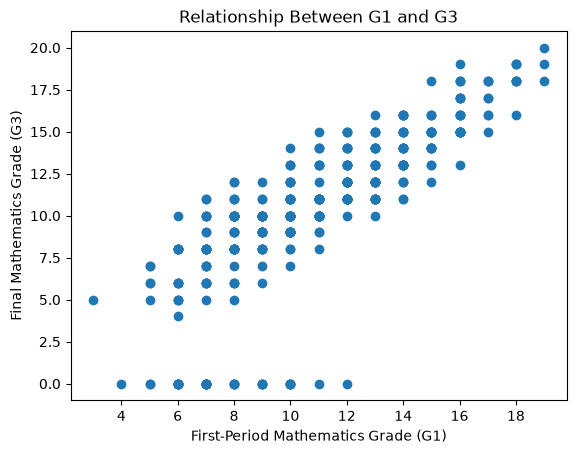

In [30]:
# Visualize the relationship G1 and G3

plt.scatter(data["G1"], data["G3"])
plt.xlabel("First-Period Mathematics Grade (G1)")
plt.ylabel("Final Mathematics Grade (G3)")
plt.title("Relationship Between G1 and G3")
plt.show()

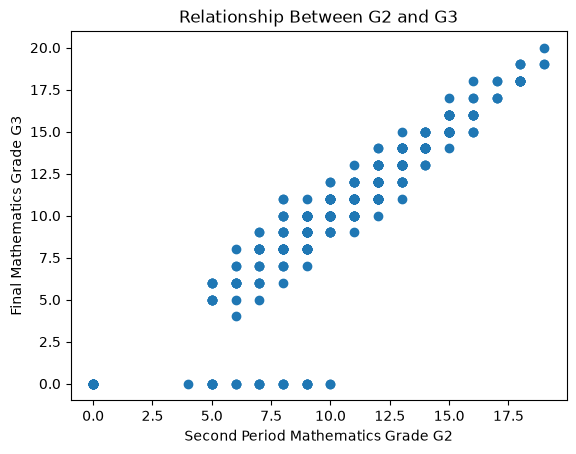

In [31]:
# Examin the relationship between G2 and G3

plt.scatter(data["G2"], data["G3"])

plt.xlabel("Second Period Mathematics Grade G2")
plt.ylabel("Final Mathematics Grade G3")
plt.title("Relationship Between G2 and G3")
plt.show()

In [32]:
# Next is to measure the relationship between G1, G2 and G3 using correlation. 
# Correlation measures the strngth and direction of the relationships between two or more numerical variables

data[["G1", "G2", "G3"]].corr()

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


## Stage 5: Prediction Timing and Data Leakage

Before selecting features for a machine learning model, it is necessary to determine when the prediction is expected to be made. 


In [74]:
# Declare X and y
# we are going to separate our data 

y = data["G3"]

X = data[["G1", "G2"]]

In [34]:
X.head()

,G1,G2
0,5,6
1,5,5
2,7,8
3,15,14
4,6,10


In [35]:
y.head()

0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

In [36]:
print(X.shape)

print(y.shape)

(395, 2)
(395,)


## Stage 6: Split the Data Before Training the Model

from sklearn.model_selection import train_test_split

In [10]:
# install scikit-learn

%conda install scikit-learn -y

Retrieving notices: done
Channels:
 - rasa
 - defaults
Platform: win-64
Solving environment: ...working... done

## Package Plan ##

  environment location: C:\Users\HP\miniconda3

  added / updated specs:
    - scikit-learn


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.10.20 |       haa95532_0         113 KB
    certifi-2026.10.19         |     pyhd3eb1b0_1         132 KB
    scikit-learn-1.9.1         |  py312h9b39bef_1         8.1 MB
    ------------------------------------------------------------
                                           Total:         8.3 MB

The following packages will be UPDATED:

  ca-certificates                      2026.8.13-haa95532_0 --> 2026.10.20-haa95532_0 
  certifi            pkgs/main/win-64::certifi-2026.7.22-p~ --> pkgs/main/noarch::certifi-2026.10.19-pyhd3eb1b0_1 
  scikit-learn                        1.9.1-py312h6c0dd63_0 

In [37]:
import sklearn
print(sklearn.__version__)

1.9.1


In [38]:
from sklearn.model_selection import train_test_split

In [39]:
# Now we split our X and y into train and test sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42
)

In [72]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(316, 2)
(79, 2)
(316,)
(79,)


### Understanding the Baseline Model

A baseline model provides a simple reference against which a machine learning model can be evaluated. For this regression problem, the mean final grade in the training set is used as the baseline prediction. The same mean value is predicted for every student in the test set.

The purpose of the baseline is not to produce the best predictions, but to establish a minimum level of performance. A useful machine learning model should perform better than this simple strategy.

In [41]:
baseline_prediction = y_train.mean()

In [42]:
print(round(baseline_prediction, 2))

10.33


This means the average baseline prediction is 10.33. Therefore, for every new student, average of 10.33 is the average score of the student
in the real sense of it, student1 = 10.33, student2 = 10.33, ...... student79 = 10.33

In [43]:
# Now lets create the baseline predictions

baseline_predictions = [baseline_prediction]* len(y_test)

In [44]:
print(baseline_predictions[:10])

[np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608), np.float64(10.325949367088608)]


## Evaluate the Baseline Model Using Mean Absolute Error

The baseline predicts the mean training grade for every student in the test set. 
To determine how well this simple strategy performs, the predicted grades are compared with the 
actual test grades using Mean Absolute Error (MAE).
MAE measures the average absolute difference between predicted and actual values.
A smaller MAE indicates better predictive performance.

In [45]:

from sklearn.metrics import mean_absolute_error

In [46]:
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

In [47]:
print(round(baseline_mae, 2))

3.65


### Baseline Model Result

The baseline model predicted the mean training-set final grade, approximately 10.33, for every student in the test set. The baseline produced a Mean Absolute Error (MAE) of 3.65.

This means that the baseline predictions differed from the students' actual final Mathematics grades by approximately 3.65 grade points on average. This value provides a reference against which subsequent machine learning models can be evaluated. A useful predictive model should ideally achieve a lower MAE than the baseline.

## Stage 8: Train the First Machine Learning Model — Linear Regression

Linear Regression will be used to learn the relationship between the predictor variables G1 and G2 and the target variable G3. The model estimates coefficients for the predictors and an intercept so that its predicted final grades fit the training observations as closely as possible.

In [48]:
from sklearn.linear_model import LinearRegression

In [49]:
model = LinearRegression()

In [50]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.16,0.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['G1','G2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.037
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [51]:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [0.16313828 0.99318622]
Intercept: -2.0370492847090205


### Interpretation of the Learned Linear Regression Model

The fitted Linear Regression model produced coefficients of approximately 0.163 for G1 and 0.993 for G2, with an intercept of approximately -2.037.

The resulting prediction equation is:

Predicted G3 = 0.163(G1) + 0.993(G2) - 2.037

The coefficient for G2 is substantially larger than that of G1, indicating that G2 has a stronger predictive relationship with the final grade within this model. Holding the other predictor constant, a one-unit increase in G2 is associated with an approximately 0.99-point increase in predicted G3, while a one-unit increase in G1 is associated with an approximately 0.16-point increase in predicted G3.

These coefficients describe predictive associations and should not be interpreted as evidence of causation.

In [52]:
predictions = model.predict(X_test)

In [53]:
print(predictions)

[ 7.21354671 12.16512128  3.41829665  8.20673293  8.36987121 12.83203093
 18.93993     6.38349878  7.21354671 12.66889264 15.14467993  6.05722221
 13.82521714 11.67570643 14.314632    7.70296157  6.2203605  10.68252021
 15.4709565   8.5330095  14.15149371 16.13786614 15.14467993  4.73775943
  8.04359464 19.76997793 10.68252021  9.19991914 17.45732893 10.68252021
  8.20673293  7.21354671 15.30781821 12.83203093  6.05722221  3.9077115
 -1.38449615 15.14467993 11.83884471  7.88045636  5.22717428 10.19310536
 14.15149371  8.36987121 15.63409478  9.689334   11.67570643 14.314632
 12.50575436 15.63409478 13.1583075  15.14467993 10.35624364  8.20673293
  3.9077115  12.50575436  9.85247228  5.89408393 15.30781821 16.627281
 12.66889264  8.20673293  7.376685    3.9077115   6.05722221 17.45732893
  8.04359464  9.52619571  9.36305743 15.30781821  7.21354671  9.36305743
 13.32144578 19.76997793 10.8456585   5.064036    8.36987121 14.314632
  3.9077115 ]


In [54]:
# Comparing Predictions With Actual Grades

results = pd.DataFrame({
    "Actual_G3": y_test.values,
    "Predicted_G3": predictions
})

results.head(10)

,Actual_G3,Predicted_G3
0,10,7.213547
1,12,12.165121
2,5,3.418297
3,10,8.206733
4,9,8.369871
5,13,12.832031
6,18,18.939930
7,6,6.383499
8,0,7.213547
9,14,12.668893


In [55]:
# Calculate Mean Absolute Error (Linear Regression MAE)

model_mae = mean_absolute_error(y_test, predictions)
print(round(model_mae, 2))

1.26


### Evaluation of the Linear Regression Model

The Linear Regression model produced a Mean Absolute Error (MAE) of approximately 1.26 on the test set.

This means that, on average, the model's predicted final Mathematics grades differed from the students' actual final grades by approximately 1.26 grade points.

The Linear Regression model performed substantially better than the baseline model, which had an MAE of 3.65. This indicates that the predictor variables G1 and G2 contain useful information for predicting students' final Mathematics grades.

# Now lets Compare Training Error and Test Error
Lets apply bias/variance thinking. We already know: 
Test MAE = 1.26
Next we need to know how well the model perform on the data it learned from. 
This step is necessary and would help identify if there is Overfitting or underfitting. 
Note: if the model performs worse on test data, that can suggest overfitting
      if it performs poorly on both, that can suggest underfitting. 

In [56]:
# Predict the Training Data

train_predictions = model.predict(X_train)
train_mae = mean_absolute_error(y_train, train_predictions)

In [57]:
print("Train MAE:", round(train_mae, 2))
print("Test MAE:", round(model_mae, 2))

Train MAE: 1.13
Test MAE: 1.26


### Training and Test Performance

The Linear Regression model achieved a training MAE of 1.13 and a test MAE of 1.26.

The relatively small difference between the training and test errors suggests that the model generalizes reasonably well to the held-out test data and does not show an obvious sign of severe overfitting on this split.

However, this conclusion is limited to the current dataset and train-test split. Further validation is required before making broader claims about model generalization.

MSE and RMSE
Now our Linear Regression model made predictions with the 79 test dataset.
We want to know how much error large predictions affect our algorithm's total error. 
MSE and RMSE will be used for this purposebecause, RMSE penalises the error while MAE does not.
Note: MSE and RMSE are performed on test data and not the training data. 

In [58]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(results["Actual_G3"], results["Predicted_G3"])
rmse = mse ** 0.5

print("Test MSE:", round(mse, 2))
print("Test RMSE:", round(rmse, 2))

Test MSE: 4.21
Test RMSE: 2.05


In [59]:
## Error Analysis
results["Absolute_Error"] = abs(results["Actual_G3"] - results["Predicted_G3"])

worse_predictions = results.sort_values("Absolute_Error", ascending = False)

worse_predictions.head(10)

,Actual_G3,Predicted_G3,Absolute_Error
19,0,8.533009,8.533009
24,0,8.043595,8.043595
8,0,7.213547,7.213547
57,0,5.894084,5.894084
64,9,6.057222,2.942778
27,12,9.199919,2.800081
0,10,7.213547,2.786453
31,10,7.213547,2.786453
62,10,7.376685,2.623315
38,14,11.838845,2.161155


In [60]:
print(y_test.head())

78     10
371    12
248     5
55     10
390     9
Name: G3, dtype: int64


In [61]:
print(predictions[:5])

[ 7.21354671 12.16512128  3.41829665  8.20673293  8.36987121]


 Calculating Residuals

A residual is the difference between a student's actual final mathematics grade (G3) and the grade predicted by our Linear Regression model.

Residual = Actual Grade − Predicted Grade

Residuals help us understand the direction of prediction errors. A positive residual means that the model predicted a grade that was too low, while a negative residual means that the model predicted a grade that was too high.

In this step, we calculate the residual for every observation in the test set. This will help us investigate where our model makes accurate predictions and where it struggles. 

In [62]:
results["Residual"] = results["Actual_G3"] - results["Predicted_G3"]

In [63]:
results.head()

,Actual_G3,Predicted_G3,Absolute_Error,Residual
0,10,7.213547,2.786453,2.786453
1,12,12.165121,0.165121,-0.165121
2,5,3.418297,1.581703,1.581703
3,10,8.206733,1.793267,1.793267
4,9,8.369871,0.630129,0.630129


In [64]:
results["Residual"]  = results["Actual_G3"] - results["Predicted_G3"]
display(results.head())

,Actual_G3,Predicted_G3,Absolute_Error,Residual
0,10,7.213547,2.786453,2.786453
1,12,12.165121,0.165121,-0.165121
2,5,3.418297,1.581703,1.581703
3,10,8.206733,1.793267,1.793267
4,9,8.369871,0.630129,0.630129


In [65]:
results["Residual"].describe()

count    79.000000
mean      0.158323
std       2.059242
min      -8.533009
25%      -0.311225
50%       0.317480
75%       1.218512
max       2.942778
Name: Residual, dtype: float64

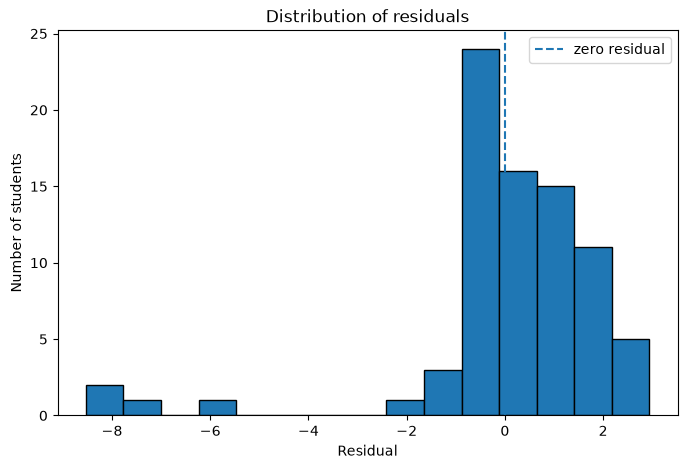

In [66]:
# A histogram to show the residual error distribution

plt.figure(figsize = (8,5))
plt.hist(results["Residual"], bins = 15, edgecolor = ("black"))
plt.axvline(0, linestyle = "--", label = "zero residual")
plt.title("Distribution of residuals")
plt.xlabel("Residual")
plt.ylabel("Number of students")
plt.legend()
plt.show()

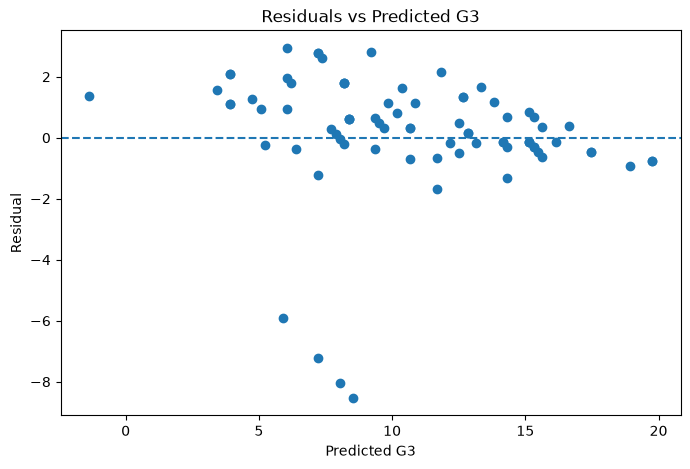

In [67]:
# Scatter plot to show if the model's error follow any noticeable pattern

plt.figure(figsize= (8, 5))
plt.scatter(results["Predicted_G3"], results["Residual"])
plt.axhline(y = 0, linestyle = "--")
plt.title("Residuals vs Predicted G3")
plt.xlabel("Predicted G3")
plt.ylabel("Residual")
plt.show()

In [68]:
# Now lets sort out residualfrom most negative to most positive

results.sort_values(by = "Residual").head(5)

,Actual_G3,Predicted_G3,Absolute_Error,Residual
19,0,8.533009,8.533009,-8.533009
24,0,8.043595,8.043595,-8.043595
8,0,7.213547,7.213547,-7.213547
57,0,5.894084,5.894084,-5.894084
13,10,11.675706,1.675706,-1.675706


In [69]:
# Lets chech if the positions of the 'results df corresponds to that of X_test
print("Result indices:", results.index[:10].tolist())
print("X_test indices:", X_test.index[:10].tolist())

Result indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
X_test indices: [78, 371, 248, 55, 390, 223, 42, 234, 316, 116]


from the output, it's obvious the index positions of the resuls df and X_test are different

In [70]:
outlier_indices = [19, 24, 8, 57]
outlier_features = X_test.iloc[outlier_indices]
display(outlier_features)

,G1,G2
334,10,9
140,7,9
316,8,8
168,6,7


In [71]:
outlier_students = data.loc[outlier_features.index]
display(outlier_students)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
334,GP,F,18,R,GT3,T,2,2,at_home,other,...,4,4,4,1,1,4,0,10,9,0
140,GP,M,15,U,GT3,T,4,3,teacher,services,...,2,2,2,1,1,3,0,7,9,0
316,GP,F,18,U,GT3,T,2,1,services,other,...,5,3,3,1,2,1,0,8,8,0
168,GP,F,16,U,GT3,T,2,2,other,other,...,5,1,5,1,1,4,0,6,7,0


In [91]:
columns_to_check = ["failures", "studytime", "schoolsup", "famsup", "paid", "health", "higher", "absences", "G1", "G2", "G3"]

display(data.loc[outlier_features.index, columns_to_check])

,failures,studytime,schoolsup,famsup,paid,health,higher,absences,G1,G2,G3
334,0,4,no,no,no,4,yes,0,10,9,0
140,0,4,yes,yes,no,3,yes,0,7,9,0
316,0,2,no,yes,yes,1,yes,0,8,8,0
168,0,2,no,yes,yes,4,yes,0,6,7,0
